# Hyper Parameter Tuning


we use hyper parameter for .if a model performance is low . \
We can boost the performance of the model by hyper parameter tuning

In [223]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,classification_report

#Load Data

In [224]:
df = pd.read_csv("/content/lung_cancer_examples.csv")
df

,Name,Surname,Age,Smokes,AreaQ,Alkhol,Result
0,John,Wick,35,3,5,4,1
1,John,Constantine,27,20,2,5,1
2,Camela,Anderson,30,0,5,2,0
3,Alex,Telles,28,0,8,1,0
4,Diego,Maradona,68,4,5,6,1
5,Cristiano,Ronaldo,34,0,10,0,0
6,Mihail,Tal,58,15,10,0,0
7,Kathy,Bates,22,12,5,2,0
8,Nicole,Kidman,45,2,6,0,0
9,Ray,Milland,52,18,4,5,1


#Data Properties

In [225]:
df.shape

(59, 7)

In [226]:
df.columns

Index(['Name', 'Surname', 'Age', 'Smokes', 'AreaQ', 'Alkhol', 'Result'], dtype='object')

In [227]:
df.isna().sum()

,0
Name,0
Surname,0
Age,0
Smokes,0
AreaQ,0
Alkhol,0
Result,0


In [228]:
df.dtypes

,0
Name,object
Surname,object
Age,int64
Smokes,int64
AreaQ,int64
Alkhol,int64
Result,int64


# drop unwanted Columns

In [229]:
df.drop(['Name','Surname'],axis=1,inplace=True)

#Count of Output

In [230]:
df['Result'].value_counts()

,count
Result,
0,31
1,28


<Axes: xlabel='Result', ylabel='count'>

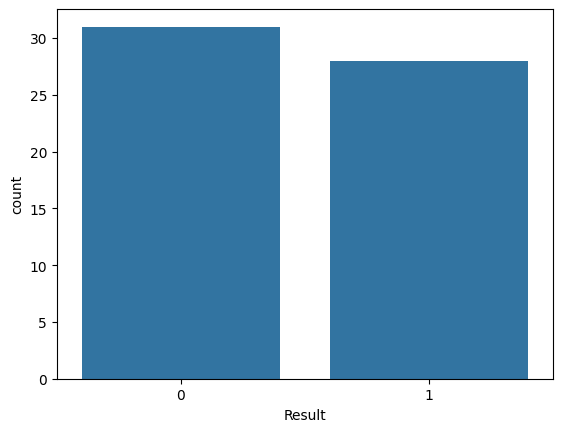

In [231]:
sns.countplot(data=df,x='Result')

# Split x,y

In [232]:
x =df.iloc[:,:-1].values
y = df.iloc[:,-1].values

In [233]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.2,random_state=2)

# Scaling the input features

In [234]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [235]:
# x_train

# Model Building

In [236]:
model = KNeighborsClassifier()
model.fit(x_train,y_train)

KNeighborsClassifier()

In [237]:
y_pred = model.predict(x_test)

In [238]:
y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0])

# Accurracy

In [239]:
score = accuracy_score(y_test,y_pred)

In [240]:
score

0.8333333333333334

In [241]:
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.75      1.00      0.86         6
           1       1.00      0.67      0.80         6

    accuracy                           0.83        12
   macro avg       0.88      0.83      0.83        12
weighted avg       0.88      0.83      0.83        12



# Tuning


1.   GridSearch Cv



In [242]:
from sklearn.model_selection import GridSearchCV

In [243]:
model1 = KNeighborsClassifier()

build a data with containing parameters

In [244]:
data = {
    "n_neighbors": [3, 5, 7, 9, 11, 15],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
    "p": [1, 2]
}

In [245]:
grd=GridSearchCV(model1,data,cv=10,scoring='accuracy')
grd.fit(x_train,y_train)

GridSearchCV(cv=10, estimator=KNeighborsClassifier(),
             param_grid={'metric': ['euclidean', 'manhattan', 'minkowski'],
                         'n_neighbors': [3, 5, 7, 9, 11, 15], 'p': [1, 2],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [246]:
print(grd.best_params_)

{'metric': 'euclidean', 'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}


In [247]:
tuned = KNeighborsClassifier(metric='euclidean',n_neighbors=3,p=1,weights='uniform')

In [248]:
tuned.fit(x_train,y_train)

KNeighborsClassifier(metric='euclidean', n_neighbors=3, p=1)

In [249]:
new_pred = tuned.predict(x_test)

In [250]:
new_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0])

In [251]:
report = classification_report(y_test,y_pred)

In [252]:
print(report)

              precision    recall  f1-score   support

           0       0.75      1.00      0.86         6
           1       1.00      0.67      0.80         6

    accuracy                           0.83        12
   macro avg       0.88      0.83      0.83        12
weighted avg       0.88      0.83      0.83        12

